In [7]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow. keras.models import Sequential


dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir=tf.keras.utils.get_file('flower_photos',origin=dataset_url,untar=True,cache_dir='.')

In [8]:
data_dir

'./datasets/flower_photos'

In [9]:
#we use this pathlib to specify a windows path
import pathlib
data_dir = pathlib.Path("./datasets/flower_photos/flower_photos")
image_count = len(list(data_dir.glob('*/*.jpg')))
print("Total images:", image_count)



Total images: 3670


In [10]:
roses=list(data_dir.glob('roses/*.jpg'))
len_roses=len(roses)
len_roses

641

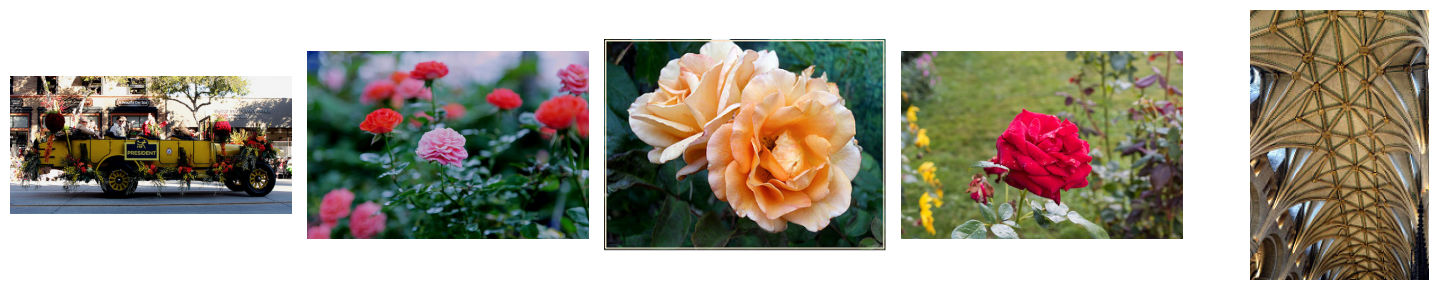

In [11]:
#THERE ARE TWO APPROACHES TO VIEW THE PICS FROM THE DATASET
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for index in range(5):
    img = PIL.Image.open(str(roses[index]))
    axes[index].imshow(img)
    axes[index].axis('off')
plt.tight_layout()
plt.show()

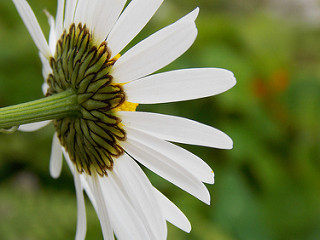

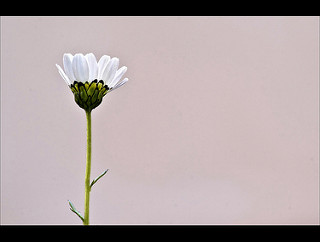

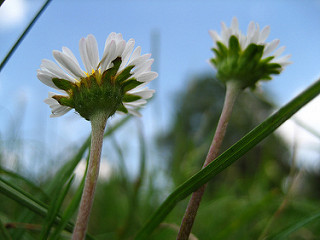

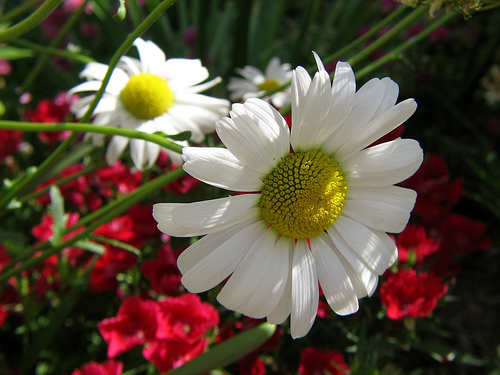

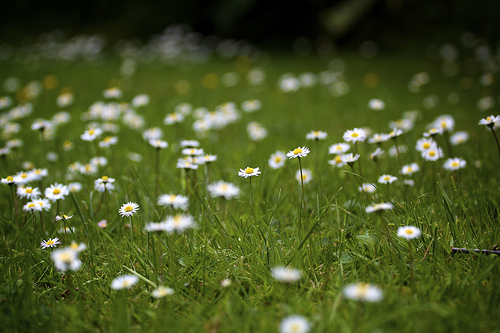

In [12]:
daisy=list(data_dir.glob('daisy/*.jpg'))
from IPython.display import display

for index in range(5):
    img = PIL.Image.open(str(daisy[index]))
    display(img)

In [13]:
flowers_images_dict={
    'roses':roses,
    'daisy':daisy,
    'dandelion':list(data_dir.glob('dandelion/*.jpg')),
    'sunflowers':list(data_dir.glob('sunflowers/*.jpg')),
    'tulips':list(data_dir.glob('tulips/*.jpg')),
}

In [14]:
flowers_label_dict={
    'roses':0,
    'daisy':1,
    'dandelion':2,
    'sunflowers':3,
    'tulips':4,
}


In [15]:
#now we will just make them into array representing diff flower images
str(flowers_images_dict['roses'][0])
img=cv2.imread(str(flowers_images_dict['roses'][0]))
img

array([[[ 14,   3,   0],
        [  1,   0,   2],
        [  0,   0,   6],
        ...,
        [244, 245, 243],
        [244, 245, 243],
        [244, 245, 243]],

       [[  0,   0,   9],
        [  0,   0,   4],
        [  4,   7,   5],
        ...,
        [243, 244, 242],
        [243, 244, 242],
        [243, 244, 242]],

       [[  3,  57, 164],
        [ 30,  63, 132],
        [  0,   0,  19],
        ...,
        [244, 245, 243],
        [244, 245, 243],
        [244, 245, 243]],

       ...,

       [[140, 105,  85],
        [146, 112,  89],
        [147, 113,  90],
        ...,
        [155, 125,  96],
        [152, 122,  93],
        [148, 118,  89]],

       [[148, 114,  91],
        [152, 118,  95],
        [150, 116,  93],
        ...,
        [154, 124,  95],
        [152, 122,  93],
        [150, 120,  93]],

       [[153, 119,  96],
        [154, 120,  97],
        [149, 115,  91],
        ...,
        [151, 122,  95],
        [153, 123,  94],
        [151, 121,  94]]

In [16]:
img.shape
#here we got to classify the roses part into a 3D array

(243, 500, 3)

In [17]:
#we need to resize the same images to get uniformity
cv2.resize(img,(180,180)).shape

(180, 180, 3)

In [18]:

for flower_name, images in flowers_images_dict.items():
    print(flower_name)
    print(len(images))

roses
641
daisy
633
dandelion
898
sunflowers
699
tulips
799


In [19]:
from PIL import Image
import numpy as np

x, y = [], []
target_size = (224, 224)

for flower_name, images in flowers_images_dict.items():
    for image in images:
        # Load image
        img = Image.open(image)

        # Resize to uniform dimensions
        img = img.resize(target_size)

        # Convert to array
        img_array = np.array(img)

        x.append(img_array)
        y.append(flowers_label_dict[flower_name])

x = np.array(x)
y = np.array(y)

print(f"x shape: {x.shape}")  # Should be (3670, 224, 224, 3)
print(f"y shape: {y.shape}")  # Should be (3670,)

x shape: (3670, 224, 224, 3)
y shape: (3670,)


In [20]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(x,y,random_state=0,test_size=0.2)

In [21]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((2936, 224, 224, 3), (734, 224, 224, 3), (2936,), (734,))

In [22]:
X_train_scaled=X_train/255
X_test_scaled=X_test/255

In [23]:
num_classes = 5

model = Sequential([
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.fit(X_train_scaled, y_train, epochs=5)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 203ms/step - accuracy: 0.4060 - loss: 1.4292
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 221ms/step - accuracy: 0.6230 - loss: 0.9761
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 226ms/step - accuracy: 0.7057 - loss: 0.7849
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 242ms/step - accuracy: 0.8069 - loss: 0.5151
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 228ms/step - accuracy: 0.8886 - loss: 0.3122


In [24]:
model.evaluate(X_test_scaled, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.6390 - loss: 1.3070


[1.307042121887207, 0.6389645934104919]

In [25]:
#we got the accuracy on fitting the model as very high on training dataset but the model failed to provide the same kinda accuracy on test dataset which provides the issue of overfitting to solve this problem we will be using DATA AUGMENTATION


In [27]:
predictions = model.predict(X_test_scaled)
print(predictions)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
[[ 0.21720113  4.3319683   1.0072044  -8.947385   -1.1410512 ]
 [ 2.3103023  -3.2049801  -4.3400545  -1.6734283   1.0044682 ]
 [-2.6109128  -2.2323086   5.072965    1.1675844  -3.2694442 ]
 ...
 [-5.7309856   9.190727   -0.11153315 -6.504284   -2.5475414 ]
 [ 0.03350621  0.9815023   5.3502994  -6.6900296  -1.5876578 ]
 [-4.306313    0.18484631 -1.0559511   2.602978    3.6226826 ]]


In [28]:
score = tf.nn.softmax(predictions [0])
score
#Just converts the same into a probability stuff

<tf.Tensor: shape=(5,), dtype=float32, numpy=
array([1.5456292e-02, 9.4651163e-01, 3.4056451e-02, 1.6179912e-06,
       3.9739623e-03], dtype=float32)>

In [29]:
np.argmax(score)


np.int64(1)

In [30]:
y_test[0]

np.int64(1)

In [32]:
#here we verified our predictions with the original stuff
#but still the accuracy is low and we need to increase the same through DATA augmentation
data_augmentation=keras.Sequential([
  layers.experimental.preprocessing.RandomFlip("horizontal",)
])
plt.axis('off')
plt.imshow(X_test_scaled[0])

AttributeError: module 'keras._tf_keras.keras.layers' has no attribute 'experimental'